In [2]:
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))
print(PROJECT_ROOT)

c:\Users\HP\numpy\diabetes-prediction


In [3]:
import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

df = pd.read_csv(PROCESSED_DIR / "diabetes_cleaned.csv")

# Remove records with missing target values
df = df.dropna(subset=["glyhb"])

# Create classification target
df["diabetes"] = (df["glyhb"] > 7.0).astype(int)

print("Dataset shape:", df.shape)
print("\nClass distribution:")
print(df["diabetes"].value_counts())

Dataset shape: (390, 18)

Class distribution:
diabetes
0    330
1     60
Name: count, dtype: int64


In [5]:
from sklearn.model_selection import train_test_split
X = df.drop(columns=["glyhb", "diabetes", "id"])
y = df["diabetes"]

X_train, X_test, y_train, y_test = train_test_split( X, y,test_size=0.2,  random_state=42,  stratify=y)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts()) 


Training shape: (312, 15)
Testing shape: (78, 15)

Training class distribution:
diabetes
0    264
1     48
Name: count, dtype: int64

Testing class distribution:
diabetes
0    66
1    12
Name: count, dtype: int64


## Train-Test Split

The dataset was divided into 80% training data and 20% testing data using `train_test_split`.

The `stratify=y` parameter was used to preserve the original class distribution in both datasets.

- Training set: 312 samples (264 non-diabetic and 48 diabetic).
- Testing set: 78 samples (66 non-diabetic and 12 diabetic).

The same training and testing sets will be used across all classification experiments to ensure a fair comparison. The testing data will remain untouched during training and class balancing.

In [13]:
from src.preprocessing.preprocessor import build_preprocessor
import joblib
from pathlib import Path

preprocessor = build_preprocessor(X_train)

X_train_weighted = preprocessor.fit_transform(X_train)
X_test_weighted = preprocessor.transform(X_test)

PROJECT_ROOT = Path.cwd().parent

PREPROCESSOR_DIR = PROJECT_ROOT / "models" / "preprocessing"
PREPROCESSOR_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(
    preprocessor,
    PREPROCESSOR_DIR / "classification_preprocessor.pkl"
)

print("Classification preprocessor saved successfully!")

Classification preprocessor saved successfully!


In [7]:
from src.classification.train import models, train_model

trained_models = {}

for name, model in models.items():
    trained_models[name] = train_model(
        model,
        X_train_weighted,
        y_train
    )

    print(f"{name} trained successfully.")

Logistic Regression trained successfully.
Random Forest trained successfully.


In [9]:
import pandas as pd
from src.classification.evaluate import evaluate_model

results = {}

for name, model in trained_models.items():
    results[name] = evaluate_model(
        model,
        X_test_weighted,
        y_test
    )

comparison = pd.DataFrame({
    name: {
        "Accuracy": result["accuracy"],
        "Precision": result["precision"],
        "Recall": result["recall"],
        "F1-score": result["f1_score"],
        "ROC-AUC": result["roc_auc"]
    }
    for name, result in results.items()
}).T

comparison.round(4)

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Logistic Regression,0.8077,0.4211,0.6667,0.5161,0.8687
Random Forest,0.8846,0.6154,0.6667,0.6400,0.9381


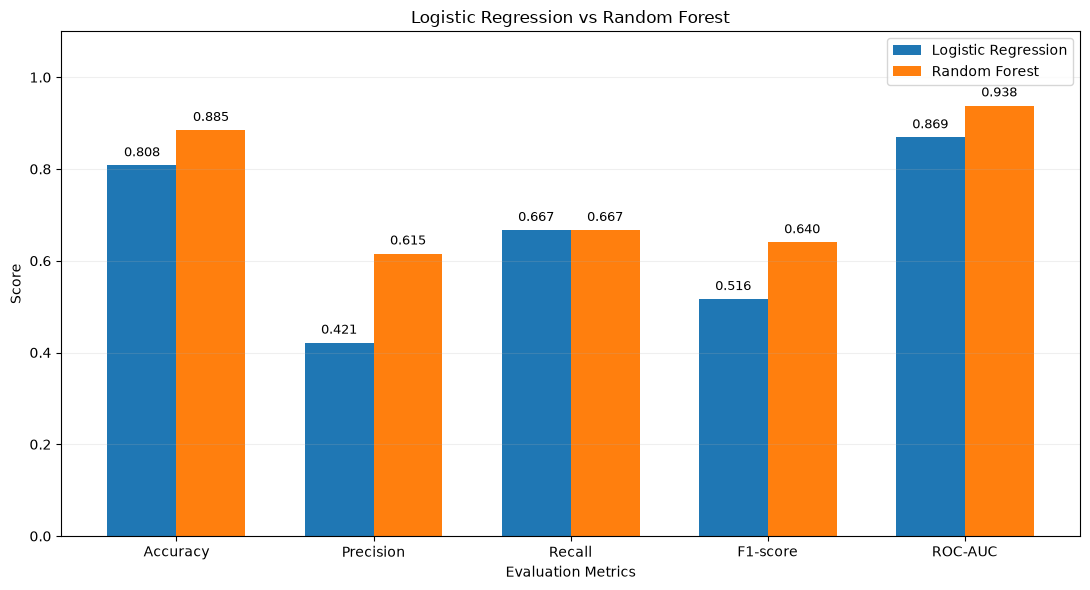

In [11]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]

logistic = comparison.loc["Logistic Regression"].values
random_forest = comparison.loc["Random Forest"].values

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(11, 6))

plt.bar(x - width/2, logistic, width, label="Logistic Regression")
plt.bar(x + width/2, random_forest, width, label="Random Forest")

plt.title("Logistic Regression vs Random Forest")
plt.ylabel("Score")
plt.xlabel("Evaluation Metrics")
plt.xticks(x, metrics)
plt.ylim(0, 1.1)

for i, value in enumerate(logistic):
    plt.text(i - width/2, value + 0.02, f"{value:.3f}",
             ha="center", fontsize=9)

for i, value in enumerate(random_forest):
    plt.text(i + width/2, value + 0.02, f"{value:.3f}",
             ha="center", fontsize=9)

plt.legend()
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

## Classification Model Training and Evaluation

In this experiment, two classification models, **Logistic Regression** and **Random Forest**, were trained using the preprocessed diabetes dataset.

Both models used class weighting (`class_weight="balanced"`) to address the imbalance between diabetic and non-diabetic cases. The same training and testing datasets were used for both models to ensure a consistent comparison.

After training, both models were evaluated on the test dataset using Accuracy, Precision, Recall, F1-score, and ROC-AUC.

The results showed that Random Forest achieved better overall performance than Logistic Regression in four evaluation metrics, while both models achieved the same recall.

A comparative bar chart was created to visualize the performance of the two models and identify the better-performing algorithm.

Based on the experimental results, **Random Forest was selected as the best-performing model among the two tested classifiers.**

In [12]:
import joblib
from pathlib import Path

best_model_name = comparison["F1-score"].idxmax()
best_model = trained_models[best_model_name]

PROJECT_ROOT = Path.cwd().parent
MODEL_DIR = PROJECT_ROOT / "models" / "classification"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

model_path = MODEL_DIR / "best_classification_model.pkl"

joblib.dump(best_model, model_path)

print("Best model:", best_model_name)
print("F1-score:", comparison.loc[best_model_name, "F1-score"])
print("Model saved to:", model_path)

Best model: Random Forest
F1-score: 0.64
Model saved to: c:\Users\HP\numpy\diabetes-prediction\models\classification\best_classification_model.pkl
